In [1]:
# ==============================================================================
# Model 2 (Advanced): Random Forest Classifier untuk Klasifikasi Kerusakan Jalan
# ==============================================================================

!pip install roboflow

from roboflow import Roboflow
import os
import time
import joblib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import hog
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 48.8 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]


In [2]:
# ------------------------------------------------------------------------------
# 1. LOAD DATASET & EKSTRAKSI FITUR (HOG + COLOR HISTOGRAM)
# ------------------------------------------------------------------------------
rf = Roboflow(api_key="W5fx36JCLXCrqI9oVuUP")
project = rf.workspace("brad-dwyer").project("pothole-voxrl")
version = project.version(1)
dataset = version.download("tensorflow")

DATASET_DIR = "/content/Pothole-1"

def load_data_and_extract_features(split_name):
    folder_path = os.path.join(DATASET_DIR, split_name)
    csv_path = os.path.join(folder_path, "_annotations.csv")
    df = pd.read_csv(csv_path)

    # Hitung rasio luas bounding box per gambar untuk menentukan label keparahan
    df['box_area'] = (df['xmax'] - df['xmin']) * (df['ymax'] - df['ymin'])
    df['img_area'] = df['width'] * df['height']
    df['box_ratio'] = df['box_area'] / df['img_area']

    df_grouped = df.groupby('filename').agg(
        pothole_count=('class', 'count'),
        area_ratio=('box_ratio', 'sum')
    ).reset_index()

    # Labeling: 0 = Low, 1 = Medium, 2 = Critical
    def get_label(row):
        if row['area_ratio'] < 0.05 and row['pothole_count'] <= 2:
            return 0
        elif row['area_ratio'] <= 0.15:
            return 1
        else:
            return 2

    df_grouped['label'] = df_grouped.apply(get_label, axis=1)

    X_features = []
    y_labels = []

    for _, row in df_grouped.iterrows():
        img_path = os.path.join(folder_path, row['filename'])
        img = cv2.imread(img_path)
        if img is None:
            continue

        # Resize ke ukuran standar 128x128 agar ekstraksi fitur konsisten & cepat
        img_resized = cv2.resize(img, (128, 128))
        gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

        # A. Ekstraksi Fitur HOG (Menangkap tepian & tekstur lubang jalan)
        hog_feat = hog(
            gray,
            orientations=9,
            pixels_per_cell=(16, 16),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            feature_vector=True
        )

        # B. Ekstraksi Fitur Color Histogram (RGB - 16 bins per channel)
        hist_b = cv2.calcHist([img_resized], [0], None, [16], [0, 256]).flatten()
        hist_g = cv2.calcHist([img_resized], [1], None, [16], [0, 256]).flatten()
        hist_r = cv2.calcHist([img_resized], [2], None, [16], [0, 256]).flatten()
        color_feat = np.concatenate([hist_b, hist_g, hist_r])
        color_feat = color_feat / (color_feat.sum() + 1e-7)  # Normalisasi

        # Gabungkan fitur HOG + Color Histogram
        combined_feat = np.concatenate([hog_feat, color_feat])
        X_features.append(combined_feat)
        y_labels.append(row['label'])

    return np.array(X_features), np.array(y_labels)

print("Mengekstrak fitur Train dan Validation set...")
X_train, y_train = load_data_and_extract_features("train")
X_val, y_val     = load_data_and_extract_features("valid")

print(f"Dimensi X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Dimensi X_val  : {X_val.shape}, y_val  : {y_val.shape}")

# Scaling fitur (penting untuk komparasi adil dengan Baseline)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Pothole-1 in tensorflow:: 100%|██████████| 673/673 [00:00<00:00, 3390.15it/s]


Mengekstrak fitur Train dan Validation set...
Dimensi X_train: (465, 1812), y_train: (465,)
Dimensi X_val  : (133, 1812), y_val  : (133,)



=== HASIL EVALUASI MODEL 2: RANDOM FOREST (VALIDATION SET) ===
Training Time   : 1.2918 detik
Accuracy        : 0.5564
Macro Precision : 0.3898
Macro Recall    : 0.4155
Macro F1-Score  : 0.3874

              precision    recall  f1-score   support

     Low (0)     0.0000    0.0000    0.0000        17
  Medium (1)     0.5208    0.7937    0.6289        63
Critical (2)     0.6486    0.4528    0.5333        53

    accuracy                         0.5564       133
   macro avg     0.3898    0.4155    0.3874       133
weighted avg     0.5052    0.5564    0.5104       133



Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


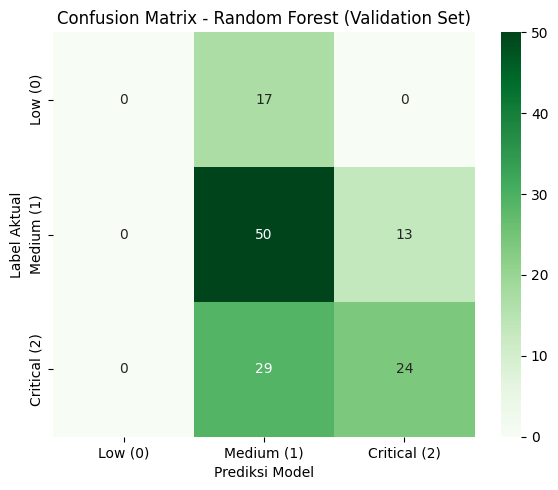

In [3]:
# ------------------------------------------------------------------------------
# 2. TRAINING MODEL 2 (ADVANCED): RANDOM FOREST CLASSIFIER
# ------------------------------------------------------------------------------
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    max_depth=None,
    min_samples_split=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

start_time = time.time()
rf_model.fit(X_train_scaled, y_train)
rf_train_time = time.time() - start_time

# Prediksi pada Validation Set
y_val_pred_rf = rf_model.predict(X_val_scaled)

# Hitung Metrik Evaluasi
CLASSES = ["Low (0)", "Medium (1)", "Critical (2)"]
rf_acc  = accuracy_score(y_val, y_val_pred_rf)
rf_prec = precision_score(y_val, y_val_pred_rf, average='macro', zero_division=0)
rf_rec  = recall_score(y_val, y_val_pred_rf, average='macro', zero_division=0)
rf_f1   = f1_score(y_val, y_val_pred_rf, average='macro', zero_division=0)

print("\n=== HASIL EVALUASI MODEL 2: RANDOM FOREST (VALIDATION SET) ===")
print(f"Training Time   : {rf_train_time:.4f} detik")
print(f"Accuracy        : {rf_acc:.4f}")
print(f"Macro Precision : {rf_prec:.4f}")
print(f"Macro Recall    : {rf_rec:.4f}")
print(f"Macro F1-Score  : {rf_f1:.4f}\n")
print(classification_report(y_val, y_val_pred_rf, target_names=CLASSES, digits=4))

# Plot Confusion Matrix Random Forest
cm_rf = confusion_matrix(y_val, y_val_pred_rf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("Confusion Matrix - Random Forest (Validation Set)")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()


=== TABEL PERBANDINGAN AWAL PADA VALIDATION SET ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Training Time (s)
0,Model 1: Logistic Regression (Baseline),0.481203,0.421289,0.418853,0.418777,0.6421
1,Model 2: Random Forest (Advanced),0.556391,0.389827,0.415494,0.387421,1.2918


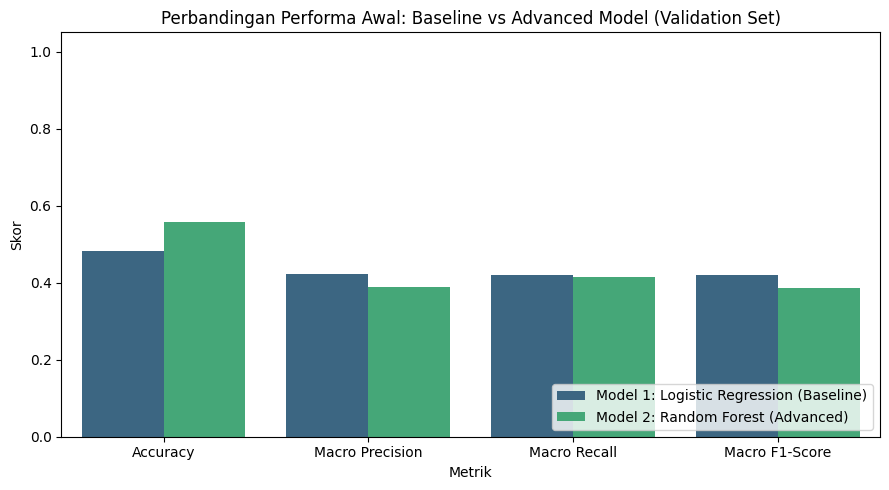

In [4]:
# ------------------------------------------------------------------------------
# 3. PERBANDINGAN AWAL: BASELINE (LOGISTIC REGRESSION) VS ADVANCED (RANDOM FOREST)
# ------------------------------------------------------------------------------
# Latih ulang Baseline dengan data yang sama untuk perbandingan langsung
start_base = time.time()
baseline_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
baseline_model.fit(X_train_scaled, y_train)
base_train_time = time.time() - start_base
y_val_pred_base = baseline_model.predict(X_val_scaled)

comparison_df = pd.DataFrame({
    "Model": ["Model 1: Logistic Regression (Baseline)", "Model 2: Random Forest (Advanced)"],
    "Accuracy": [
        accuracy_score(y_val, y_val_pred_base),
        rf_acc
    ],
    "Macro Precision": [
        precision_score(y_val, y_val_pred_base, average='macro', zero_division=0),
        rf_prec
    ],
    "Macro Recall": [
        recall_score(y_val, y_val_pred_base, average='macro', zero_division=0),
        rf_rec
    ],
    "Macro F1-Score": [
        f1_score(y_val, y_val_pred_base, average='macro', zero_division=0),
        rf_f1
    ],
    "Training Time (s)": [
        round(base_train_time, 4),
        round(rf_train_time, 4)
    ]
})

print("\n=== TABEL PERBANDINGAN AWAL PADA VALIDATION SET ===")
display(comparison_df)

# Visualisasi Perbandingan Metrik
comparison_melted = comparison_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-Score"],
    var_name="Metrik",
    value_name="Skor"
)

plt.figure(figsize=(9, 5))
sns.barplot(data=comparison_melted, x="Metrik", y="Skor", hue="Model", palette="viridis")
plt.ylim(0, 1.05)
plt.title("Perbandingan Performa Awal: Baseline vs Advanced Model (Validation Set)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [5]:
# ------------------------------------------------------------------------------
# 4. SIMPAN MODEL UNTUK REPRODUKTIFITAS
# ------------------------------------------------------------------------------
os.makedirs("Models", exist_ok=True)
joblib.dump(rf_model, "Models/rf_advanced_initial.pkl")
joblib.dump(scaler, "Models/feature_scaler.pkl")
print("Model berhasil disimpan ke Models/rf_advanced_initial.pkl")

Model berhasil disimpan ke Models/rf_advanced_initial.pkl
